In [1]:
import polars as pl
import numpy as np
import polars.selectors as sl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sentence_transformers import SentenceTransformer, util 
from itertools import combinations
import re

pl.Config.set_fmt_str_lengths(500)
pl.Config.set_tbl_rows(-1)

polars.config.Config

In [2]:
#file_path = Path('../outputs/LLM/glint/risultati_llm_20261115_193713.csv')
# file_path = Path('../outputs/LLM/glint/risultati_llm_20261114_162646.csv')
file_path = Path('../outputs/LLM/cfd/risultati_llm_20261121_165721.csv')
df = pl.read_csv(
    file_path,
    separator=',',
    infer_schema_length=None
).drop(
    ['timestamp']
)

df.head(5)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: slightly uneven background; image slightly too dark or bright; head too small in the frame Good aspects: eyes open; no head covering; even lighting on the face; proper space above the head; proper space below the face""","""The photo features a face with open eyes, no head covering, and even lighting, despite a slightly uneven background and slightly off lighting. The subject's face is well-proportioned, with adequate space around the head and below the face.""",38,0.21,92,49
"""LFM2-1.2B""","""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; image clearly too dark or too bright; slightly improper space below the face Good aspects: no head covering; even lighting on the face; head of adequate size; proper space above the head""","""The face photo shows partially closed eyes, a cluttered background, and uneven lighting, but the subject's face is well-lit, head size is adequate, and there's proper space above the head.""",30,0.16,98,43
"""LFM2-1.2B""","""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; cluttered, non-uniform background; image slightly too dark or bright; improper space above the head; improper space below the face Good aspects: no head covering; even lighting on the face; head of adequate size""","""The face photo features closed eyes, a cluttered background, and uneven lighting, but the subject's head is appropriately sized and the lighting is even. The face itself is well-lit and clear.""",31,0.15,98,42
"""LFM2-1.2B""","""CFD-BF-029-005-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; image clearly too dark or too bright; improper space above the head; improper space below the face Good aspects: no head covering; uniform background; even lighting on the face; head of adequate size""","""The face photo shows eyes partially closed, with uneven lighting, and improper spacing above and below the head, lacking a head covering. Despite these flaws, the face is well-lit and the expression is neutral.""",34,0.15,91,43
"""LFM2-1.2B""","""CFD-WF-005-027-F.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: slightly uneven background; strongly uneven lighting on the face; improper space above the head Good aspects: eyes open; no head covering; well exposed image; head of adequate size; proper space below the face""","""The photo features a face with open eyes, no head covering, and proper lighting, but suffers from uneven lighting and background and head space issues. Despite these flaws, the face is well-exposed and the head size is adequate.""",38,0.16,88,47


In [3]:
import base64, html, io
from pathlib import Path

import polars as pl
from PIL import Image
from IPython.display import HTML, display


def mostra_tabella(df, shards_dir, cols=None, n=5, files=None, seed=0, width=110, file_col="file"):
    """Una riga per immagine: miniatura + le colonne del DataFrame.
    df         : DataFrame con una colonna 'file' (nome dell'immagine) e le altre colonne da mostrare
    shards_dir : cartella che contiene shard_00000, shard_00001, ...
    cols       : colonne da mostrare (default: tutte tranne 'file' e 'prompt')"""
    index = {p.name: p for p in Path(shards_dir).expanduser().glob("shard_*/*")
             if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".ppm"}}

    if files is None:
        tutti = df[file_col].unique(maintain_order=True)
        files = tutti.sample(min(n, len(tutti)), seed=seed).to_list()
    cols = cols or [c for c in df.columns if c not in (file_col, "prompt")]
    sub = {r[file_col]: r for r in df.filter(pl.col(file_col).is_in(files)).iter_rows(named=True)}

    def miniatura(name):
        if name not in index:
            return "<i>immagine non trovata</i>"
        im = Image.open(index[name]).convert("RGB")
        im.thumbnail((width * 2, width * 3))
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=80)
        return f'<img src="data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}" width="{width}">'

    def testo(v):
        if v is None:
            return "-"
        return html.escape("; ".join(map(str, v)) if isinstance(v, list) else str(v))

    righe = []
    for f in files:
        r = sub.get(f, {})
        nome = Path(f).name
        celle = [f"<td>{miniatura(nome)}<br><small>{html.escape(nome)}</small></td>"]
        celle += [f"<td>{testo(r.get(c))}</td>" for c in cols]
        righe.append("<tr>" + "".join(celle) + "</tr>")

    css = ("<style>.tm{border-collapse:collapse;font-size:13px}.tm td,.tm th{border:1px solid #ccc;"
           "padding:6px;vertical-align:top;max-width:260px;word-wrap:break-word;text-align:left}"
           ".tm th{background:#f2f2f2}</style>")
    intest = "".join(f"<th>{html.escape(str(c))}</th>" for c in cols)
    display(HTML(f"{css}<table class='tm'><tr><th>immagine</th>{intest}</tr>" + "".join(righe) + "</table>"))

In [4]:
df.head(1)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: slightly uneven background; image slightly too dark or bright; head too small in the frame Good aspects: eyes open; no head covering; even lighting on the face; proper space above the head; proper space below the face""","""The photo features a face with open eyes, no head covering, and even lighting, despite a slightly uneven background and slightly off lighting. The subject's face is well-proportioned, with adequate space around the head and below the face.""",38,0.21,92,49


immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-241-222-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: head slightly small in the frame; slightly improper space below the face Good aspects: eyes open; neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; proper space above the head","The face photo shows a neutral expression with eyes open, set against a uniform background with even lighting on the face. The image is well-exposed, with the head positioned to leave proper space above, despite being slightly small in the frame and having inadequate space below.",46,0.81,115,54
CFD-AM-229-224-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; slightly uneven lighting; improper space above the head; improper space below the face Good aspects: no head covering; uniform background; well exposed image; head of adequate size","The passport-style face photo shows a person with a clearly non-neutral expression, eyes mostly closed, and slightly uneven lighting. The image is well-exposed with a uniform background, but has issues with the space above and below the face.",38,0.72,115,48
CFD-BM-033-038-F.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; image slightly too dark or bright; improper space above the head; improper space below the face Good aspects: no head covering; even lighting on the face; head of adequate size","The passport-style face photo shows a person with even lighting on their face, no head covering, and a head of adequate size. However, the image has issues with the eyes being partly closed, uneven background, and improper spacing above and below the face.",43,0.77,114,52
CFD-MF-353-204-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; head too small in the frame Good aspects: neutral expression; no head covering; uniform background; even lighting on the face; well exposed image; proper space above the head; proper space below the face","The face photo shows a neutral expression with even lighting, a uniform background, and proper space above and below the face. However, the image is marred by partly closed eyes and a head that appears too small in the frame.",40,0.72,115,47
CFD-BF-209-172-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; slightly uneven lighting; slightly improper space above the head; improper space below the face Good aspects: neutral expression; no head covering; uniform background; well exposed image; head of adequate size","The passport-style face photo shows a neutral expression with no head covering, set against a uniform background with good exposure. However, it has some issues with the eyes being mostly closed, uneven lighting, and improper spacing above and below the face.",41,0.74,114,49
CFD-AM-233-236-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; slightly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; improper space above the head; improper space below the face Good aspects: no head covering; well exposed image; head of
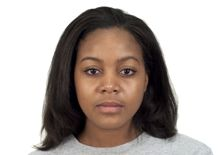
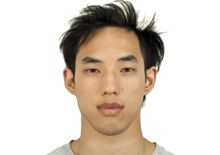
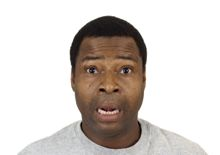
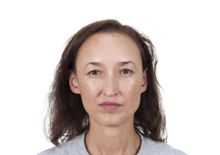
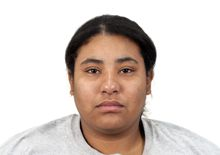
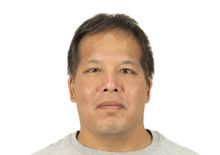
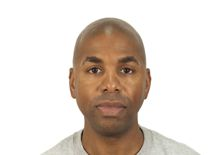
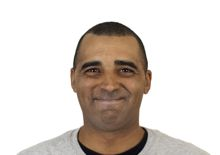
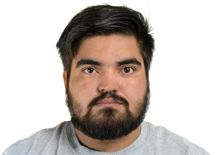
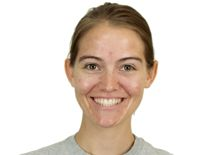
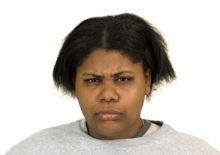
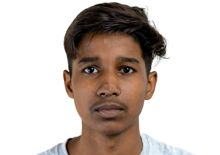
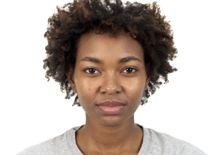
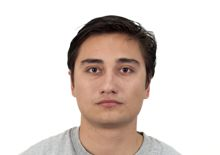
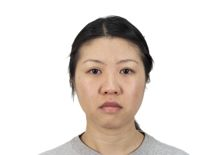
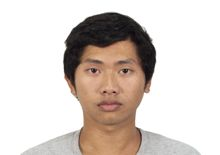
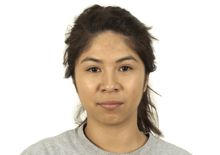
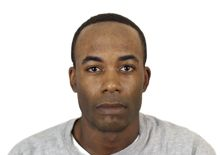
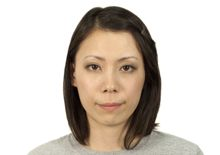
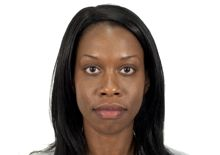
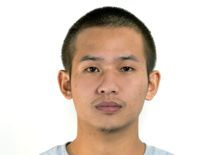
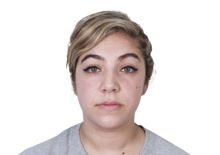
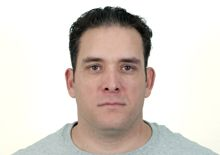
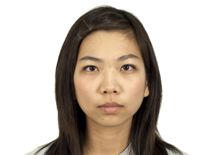
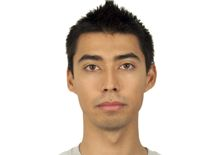
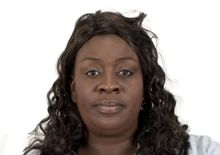
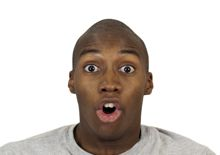
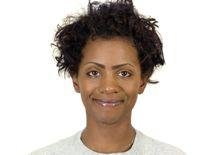
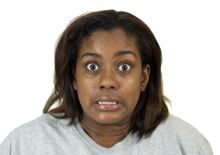
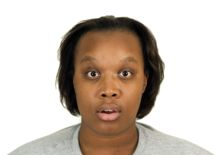
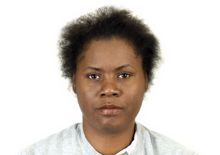
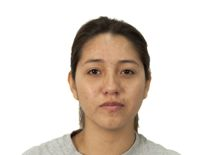
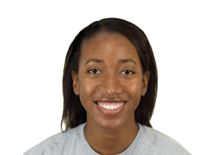
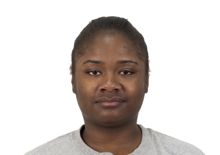
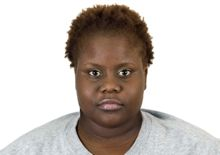
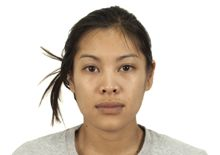
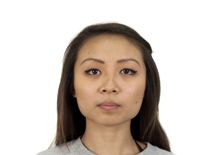
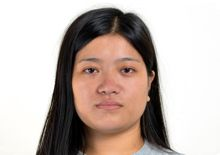
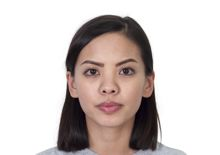
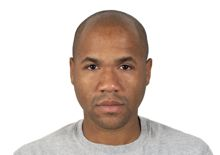
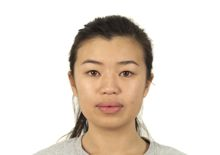
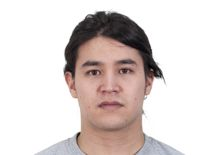
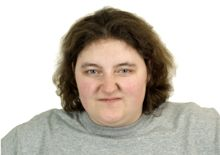
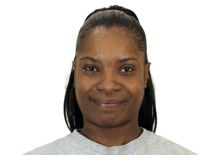
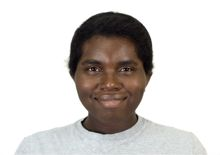
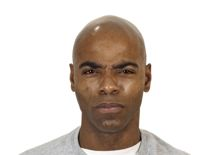
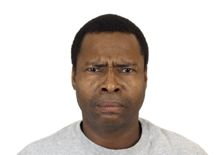
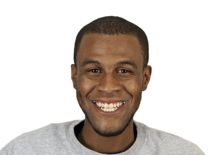
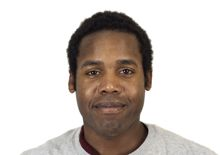
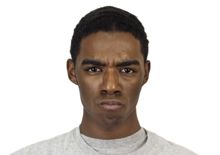
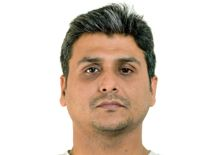
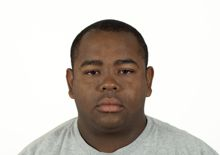
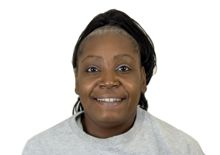
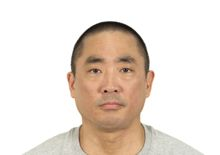
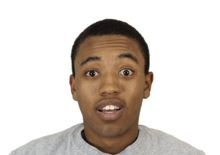
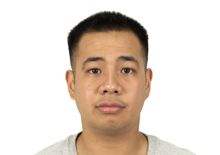
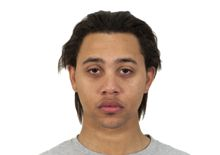
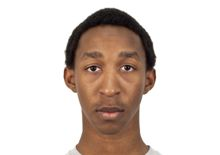
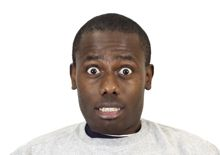
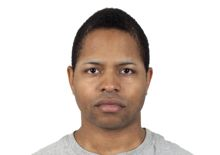
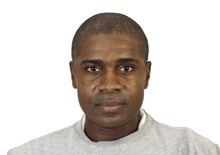
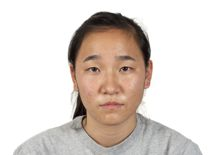
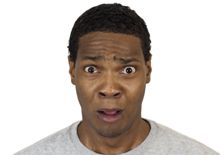
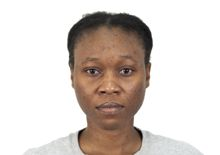
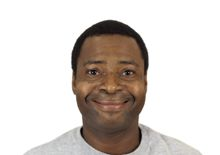
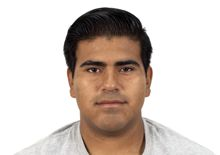
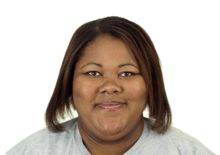
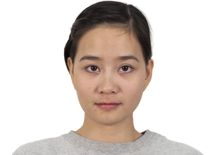
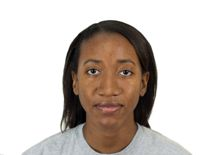
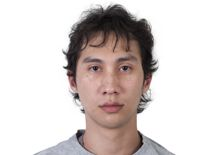
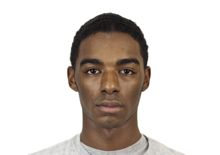
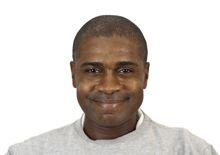
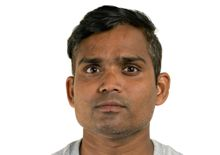
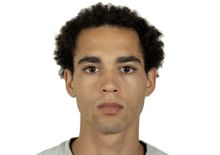
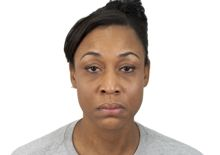

In [6]:
mostra_tabella(df, "~/prove/cfd_all/images", n=75,
               cols=["modello", "prompt", "risposta", "num_parole",
                     "tempo_s", "prompt_tokens", "completion_tokens"])